# Heat generation and convection: Çengel Example 5-3

Solving the nine-node coefficient system used in the coursework example. The plot shows temperature by node; a spatial contour needs the original node-position diagram.

Nodal temperatures (°C): [112.102 110.786 106.553 109.393 108.135 103.16   97.339  96.256  97.604]


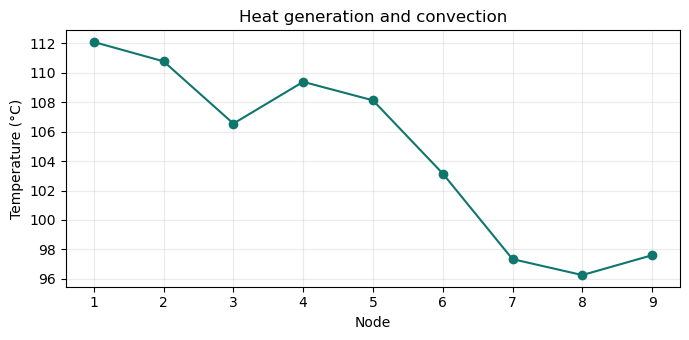

In [1]:
import numpy as np

h = 80         
l = 1.2e-2     
k = 15         
e = 2e6        
Ti = 25        
q = 5e3        

A = np.array([
    [-(2 + h*l/k), 1, 0, 1, 0, 0, 0, 0, 0],          
    [1, -(4 + 2*h*l/k), 1, 0, 2, 0, 0, 0, 0],        
    [0, 1, -(2 + 2*h*l/k), 0, 0, 1, 0, 0, 0],        
    [1, 0, 0, -4, 2, 0, 0, 0, 0],                    
    [0, 1, 0, 1, -4, 1, 0, 0, 0],                    
    [0, 0, 1, 0, 2, -(6 + 2*h*l/k), 1, 0, 0],        
    [0, 0, 0, 0, 0, 1, -(4 + 2*h*l/k), 1, 0],        
    [0, 0, 0, 0, 0, 0, 1, -(4 + 2*h*l/k), 1],        
    [0, 0, 0, 0, 0, 0, 0, 1, -(2 + h*l/k)]           
])

B = np.array([
    -((h*l*Ti/k) + (e*l**2/(2*k))),                    
    -((2*h*l*Ti/k) + (e*l**2/k)),                      
    -((2*h*l*Ti/k) + (e*l**2/(2*k))),                  
    -(90 + (e*l**2/k)),                                
    -(90 + (e*l**2/k)),                                
    -((180 + 2*h*l*Ti/k) + (3*e*l**2/(2*k))),          
    -((180 + 2*h*l*Ti/k) + (e*l**2/k)),                
    -((180 + 2*h*l*Ti/k) + (e*l**2/k)),                
    -((90 + q*l/k + h*l*Ti/k) + (e*l**2/(2*k)))        
])

T = np.linalg.solve(A, B)

print('Nodal temperatures (°C):', np.round(T, 3))
assert np.allclose(A @ T, B)
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(np.arange(1, 10), T, 'o-', color='#0f766e')
ax.set(xlabel='Node', ylabel='Temperature (°C)', title='Heat generation and convection')
ax.set_xticks(np.arange(1, 10))
ax.grid(alpha=.25)
plt.tight_layout()
plt.show()